# 03B · Dimensiones temáticas experimentales · SiteWise

**Objetivo:** proporcionar cinco dimensiones comparables para la decisión conjunta Data + ML. No selecciona entradas finales, no entrena clustering y no modifica v03/v04 candidata.

## Resumen
Se utilizan percentiles empíricos de la población municipal disponible, con pesos iguales únicamente como referencia experimental. La ausencia de un componente deja el índice sin valor. Se conservan alternativas y componentes originales. Los índices no son probabilidades ni puntuaciones de inversión.

**Ejecución de referencia con los datos reales recibidos:** 8.132 municipios; cinco dimensiones completas para 3,615 con JRC y 3,022 con MITECO. No se seleccionan ni imputan entradas definitivas.

## 1. Datos y controles
Entrada: `data/processed/sitewise_v04_candidata/` (03A). Salida: `data/processed/sitewise_dimensiones_v01/`. No depende de notebooks 04–11.

In [1]:
from pathlib import Path
import itertools
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/processed/sitewise_v04_candidata').is_dir())
BASE = ROOT / 'data/processed/sitewise_v04_candidata'
OUT = ROOT / 'data/processed/sitewise_dimensiones_v01'
municipal = pd.read_csv(BASE / 'dataset_municipal.csv', dtype={'cod_ine': str, 'cod_provincia': str}, low_memory=False)
N = len(municipal)
assert N == 8132 and municipal.cod_ine.is_unique
assert municipal.cod_ine.str.fullmatch(r'\d{5}').all()
assert municipal.superficie_km2.gt(0).all()
print('Municipios:', N)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

Municipios: 8132


## 2. Definiciones exploratorias
Percentil de rango medio: `100 * (rango - 0.5) / n`, con empates compartiendo rango. Distancias invertidas (`100 - percentil`). Se exige que todos los componentes estén presentes, no se imputan datos. Se usa el conjunto municipal completo solo para esta exploración descriptiva; ML debe decidir y versionar la transformación final.

- Logística: mayor presencia industrial y proximidad a infraestructuras.
- Agua: mayor presión y peor estado cuantitativo (no disponibilidad de suministro).
- Naturales: mayor frecuencia histórica de incendios y superficie T100 modelizada/cartografiada; JRC y MITECO se mantienen como alternativas, no se combinan. No representa probabilidad de daño.
- Socioeconómico: mayor densidad y crecimiento demográfico, no necesariamente mayor atractivo. Variante de empleo separada (paro registrado por habitante, no tasa de paro).
- Recursos: mayor recurso solar/eólico y cobertura de telecomunicaciones. No es una medida de capacidad energética ni un índice de atractivo universal; se conservan energía y conectividad separadas. Electricidad provincial fuera de las candidatas.

Pesos iguales elegidos como **baseline**, no aprobados ni calibrados. La heterogeneidad de los bloques puede justificar no agregarlos.

In [2]:
d = municipal.set_index('cod_ine').copy()
aux = 'paro_por_100_hab_observado'
publicado = d['estado__paro_total'].isin(['real','publicado','agregado_fusion_documentada'])
d[aux] = (100*d.paro_total/d.poblacion_2025).where(publicado & d.paro_total.ge(0) & d.poblacion_2025.gt(0))
# (variable, direccion). Direccion -1 solo cuando menor distancia implica mayor proximidad.
defs = {
 'dimension_logistica': [('suelo_industrial_cartografiado_pct',1),('dist_recta_eje_autovia_km',-1),('dist_recta_ttm_km',-1)],
 'dimension_hidrica': [('estres_hidrico_pct',1),('agua_subterranea_mal_estado_cuantitativo_pct',1)],
 'dimension_natural_jrc': [('incendios_ge1ha_100km2_anio',1),('jrc_t100_area_positiva_pct',1)],
 'dimension_natural_miteco': [('incendios_ge1ha_100km2_anio',1),('miteco_t100_area_pct',1)],
 'dimension_socioeconomica': [('densidad_hab_km2',1),('variacion_poblacion_pct',1)],
 'dimension_recursos': [('irradiacion_ghi_kwh_m2_anio',1),('viento_100m_media_m_s',1),('cobertura_ftth_pct',1),('cobertura_5g_pct',1)],
 'alternativa_energia': [('irradiacion_ghi_kwh_m2_anio',1),('viento_100m_media_m_s',1)],
 'alternativa_conectividad': [('cobertura_ftth_pct',1),('cobertura_5g_pct',1)],
 'alternativa_estres_hidrico': [('estres_hidrico_pct',1)],
 'alternativa_empleo': [(aux,1)]}
principal = ['dimension_logistica','dimension_hidrica','dimension_natural_jrc','dimension_socioeconomica','dimension_recursos']
variables = sorted({v for spec in defs.values() for v,_ in spec})
assert all(v in d for v in variables)
X = d[variables].apply(pd.to_numeric, errors='raise')
assert not np.isinf(X.to_numpy()).any()
for v in ['jrc_t100_area_positiva_pct','miteco_t100_area_pct','agua_subterranea_mal_estado_cuantitativo_pct']:
    assert X[v].dropna().between(0,100).all()
R = X.rank(method='average').sub(.5).div(X.count()).mul(100)
indices = pd.DataFrame(index=d.index)
componentes = pd.DataFrame(index=d.index)
metodo = []
for name, spec in defs.items():
    C = pd.DataFrame({v: R[v] if sign==1 else 100-R[v] for v,sign in spec})
    indices[name] = C.mean(axis=1, skipna=False)
    assert indices[name].notna().equals(X[[v for v,_ in spec]].notna().all(axis=1))
    assert indices[name].dropna().between(0,100).all()
    for v,sign in spec:
        componentes[f'{name}__{v}'] = C[v]
        metodo.append({'dimension':name,'indicador':v,'direccion':sign,'peso_baseline':1/len(spec),'n_valores':int(X[v].count())})
metodo = pd.DataFrame(metodo)
print('No se han imputado valores ni entrenado modelos.')

No se han imputado valores ni entrenado modelos.


## 3. Cobertura y elección conjunta
Se muestran las alternativas y cuántos municipios podrían entrar en cada combinación de 3 o 4 dimensiones sin imputación. No es una recomendación automática de selección.

,municipios_con_valor,municipios_pendientes,disponibilidad_pct
dimension_logistica,7971,161,98.02
dimension_hidrica,7389,743,90.86
dimension_natural_jrc,4026,4106,49.51
dimension_natural_miteco,3214,4918,39.52
dimension_socioeconomica,8132,0,100.00
dimension_recursos,8130,2,99.98
alternativa_energia,8130,2,99.98
alternativa_conectividad,8132,0,100.00
alternativa_estres_hidrico,8108,24,99.70
alternativa_empleo,6280,1852,77.23


,fuente_natural,n_dimensiones,dimensiones,municipios_completos,disponibilidad_pct
15,JRC,5,dimension_logistica; dimension_hidrica; dimens...,3615,44.45
31,MITECO,5,dimension_logistica; dimension_hidrica; dimens...,3022,37.16


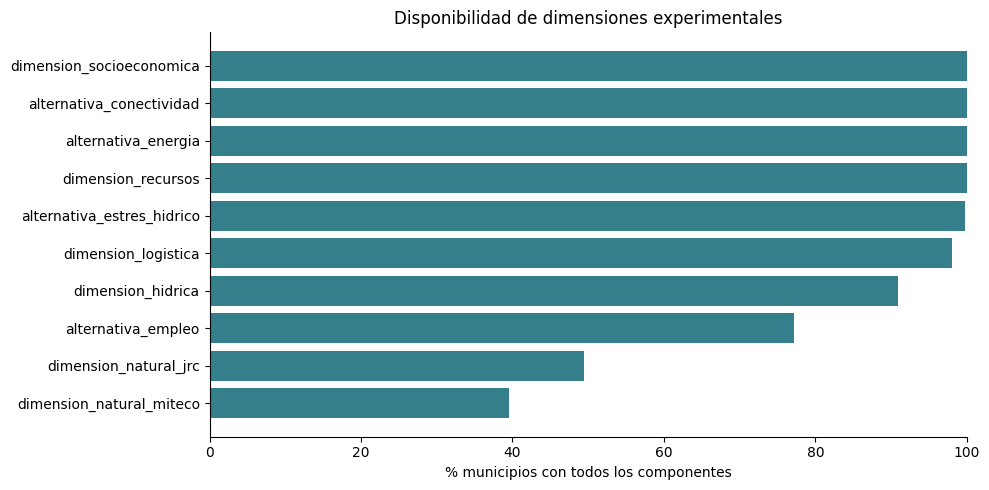

In [3]:
cobertura = indices.notna().sum().rename('municipios_con_valor').to_frame()
cobertura['municipios_pendientes'] = N - cobertura.municipios_con_valor
cobertura['disponibilidad_pct'] = 100*cobertura.municipios_con_valor/N
display(cobertura.round(2))
comb = []
for variante in ['JRC','MITECO']:
    candidatos = principal if variante=='JRC' else [v.replace('natural_jrc','natural_miteco') for v in principal]
    for k in [3,4,5]:
        for vs in itertools.combinations(candidatos,k):
            n=int(indices[list(vs)].notna().all(axis=1).sum())
            comb.append({'fuente_natural':variante,'n_dimensiones':k,'dimensiones':'; '.join(vs),'municipios_completos':n,'disponibilidad_pct':100*n/N})
comb = pd.DataFrame(comb)
display(comb[comb.n_dimensiones.eq(5)].round(2))
fig,ax=plt.subplots(figsize=(10,5))
p=cobertura.disponibilidad_pct.sort_values()
ax.barh(p.index,p,color='#357f8d'); ax.set(xlim=(0,100),xlabel='% municipios con todos los componentes',title='Disponibilidad de dimensiones experimentales'); fig.tight_layout(); plt.show(); plt.close(fig)

## 4. Distribuciones, redundancia y sensibilidad
Las dimensiones pueden perder información al promediar componentes. Las correlaciones se calculan sobre pares disponibles y se conservan sus tamaños muestrales. La sensibilidad compara cada índice con variantes que duplican el peso de un componente; no propone pesos finales.

,dimension,componente_doble,n,rho_spearman,mediana_cambio_abs,p95_cambio_abs
0,dimension_logistica,suelo_industrial_cartografiado_pct,7971,0.977,2.939,8.701
1,dimension_logistica,dist_recta_eje_autovia_km,7971,0.977,3.130,8.724
2,dimension_logistica,dist_recta_ttm_km,7971,0.973,3.213,9.154
3,dimension_hidrica,estres_hidrico_pct,7389,0.984,3.683,9.656
4,dimension_hidrica,agua_subterranea_mal_estado_cuantitativo_pct,7389,0.989,3.683,9.656
5,dimension_natural_jrc,incendios_ge1ha_100km2_anio,4026,0.963,4.133,12.020
6,dimension_natural_jrc,jrc_t100_area_positiva_pct,4026,0.961,4.133,12.020
7,dimension_natural_miteco,incendios_ge1ha_100km2_anio,3214,0.961,4.017,12.365
8,dimension_natural_miteco,miteco_t100_area_pct,3214,0.959,4.017,12.365
9,dimension_socioeconomica,densidad_hab_km2,8132,0.972,3.527,11.389


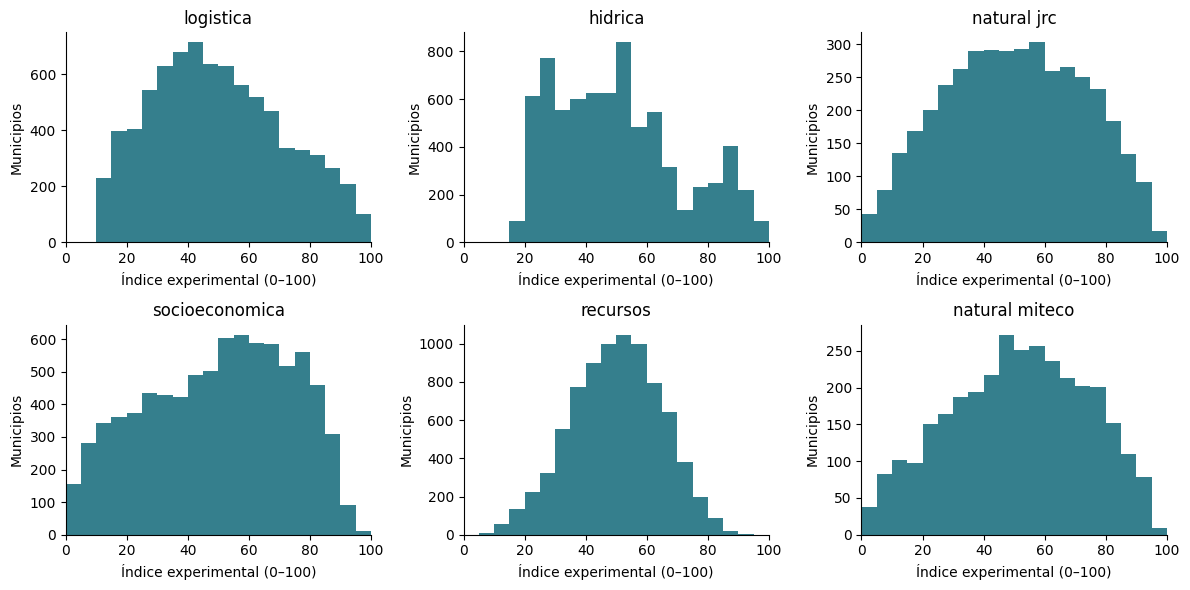

In [4]:
pares=[]; sensibilidad=[]
for a,b in itertools.combinations(indices.columns,2):
    z=indices[[a,b]].dropna()
    pares.append({'a':a,'b':b,'n_pares':len(z),'rho_spearman':z[a].corr(z[b],method='spearman') if len(z)>1 else np.nan})
for name,spec in defs.items():
    if len(spec)<2: continue
    C=componentes[[f'{name}__{v}' for v,_ in spec]].dropna()
    for v,_ in spec:
        alt=(C.sum(axis=1)+C[f'{name}__{v}'])/(len(spec)+1)
        base=indices.loc[C.index,name]
        sensibilidad.append({'dimension':name,'componente_doble':v,'n':len(C),'rho_spearman':base.corr(alt,method='spearman'),'mediana_cambio_abs':(base-alt).abs().median(),'p95_cambio_abs':(base-alt).abs().quantile(.95)})
pares=pd.DataFrame(pares); sensibilidad=pd.DataFrame(sensibilidad)
display(sensibilidad.round(3))
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,name in zip(axes.flat,principal+['dimension_natural_miteco']):
    ax.hist(indices[name].dropna(),bins=np.arange(0,105,5),color='#357f8d'); ax.set(xlim=(0,100),title=name.replace('dimension_','').replace('_',' '),xlabel='Índice experimental (0–100)',ylabel='Municipios')
fig.tight_layout(); plt.show(); plt.close(fig)

## 5. Exportación y decisión pendiente
La matriz principal tiene cinco columnas candidatas (más código INE), con JRC como variante de referencia para mostrar resultados, no como fuente elegida. La matriz de alternativas permite sustituirla por MITECO o estudiar subdimensiones. Los huecos se mantienen. Antes de usar en ML: revisión conjunta de significado, cobertura, sensibilidad, tratamiento de ausencias y estabilidad. No usar para evaluar una parcela.

In [5]:
OUT.mkdir(parents=True,exist_ok=True)
def guardar(t,nombre): t.to_csv(OUT/nombre,index=False,encoding='utf-8-sig')
guardar(indices[principal].reset_index(),'cinco_dimensiones_candidatas.csv')
guardar(indices.reset_index(),'dimensiones_y_alternativas.csv')
guardar(componentes.reset_index(),'componentes_percentiles.csv')
guardar(cobertura.rename_axis('dimension').reset_index(),'cobertura_dimensiones.csv')
guardar(comb,'cobertura_combinaciones.csv')
guardar(pares,'correlaciones_dimensiones.csv')
guardar(sensibilidad,'sensibilidad_pesos.csv')
guardar(metodo,'metodologia_dimensiones.csv')
guardar(pd.DataFrame([{'archivo':'dataset_municipal.csv','sha256':hashlib.sha256((BASE/'dataset_municipal.csv').read_bytes()).hexdigest(),'municipios':N}]),'manifest_entrada.csv')
assert len(pd.read_csv(OUT/'cinco_dimensiones_candidatas.csv',dtype={'cod_ine':str}))==N
print('Salidas:',OUT.relative_to(ROOT))

Salidas: data\processed\sitewise_dimensiones_v01
